# SokoRadar 04: recommender ("where to buy")
**Question:** when a price rise is forecast for a crop in one county, can we point the buyer to a nearby county where the same crop is cheaper, and does the forecast help choose it?

**Why this form.** A recommender normally learns from user history. We have none, so the recommendation is built from **prices and forecasts only**: a rule-based "where to buy" for the four staples with a chosen ARIMA order (dry maize, sorghum, Rosecoco beans, red Irish potatoes), wholesale and retail kept separate.


| Step | What it does |
|---|---|
| Alert | In each crop, price type, month and horizon, the **top 20%** of counties by forecast rise (and above zero) get an alert. |
| Candidates | Counties whose centre is within **200 km**, and that have a **real (observed) price at the alert month**. |
| Recommend | The candidate with the lowest forecast price, if it is at least **5%** below the alert county's forecast. |
| Score | Only where both counties have a real price at the target month: was the recommended county really cheaper, and by how much (KES/kg and %)? |
| Compare | Same alerts, four ways to choose: the model (cheapest forecast), **cheapest today** (the naive baseline), a random neighbour, and a ceiling that peeks at the future. |

## 1. Data and harness
The next two cells are the group harness (target table, yearly folds, naive and ARIMA models) restricted to the four core crops. The ARIMA backtest is the slow part (about 5 minutes the first time) and is cached to `forecasts_core_backtest.csv`, so later runs take seconds. The table below is the harness check: **MAE % on observed prices**, the same measure used for M1 to M5.

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

LONG = 'SokoRadar_County_2006_2024_long.csv'
# find the two data files next to this notebook, in a parent folder, or in sokoradar_raw_data / output (repo layout)
def find(name):
    here = Path.cwd()
    for p in [here, *here.parents]:
        for sub in ('', 'output', 'sokoradar_raw_data'):
            if (p / sub / name).exists(): return p / sub / name
    raise FileNotFoundError(f'{name} not found in {here} or any parent folder')
DATA_PATH, COUNTIES_PATH = find(LONG), find('counties.csv')

BACKTEST_YEARS = list(range(2015, 2025))      # same yearly folds as the group harness (2015-2024 only; 2025-26 is NOT touched)
HORIZONS = [1, 2, 3]
CORE = ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes']   # the four staples that have a chosen ARIMA order

In [2]:
prices = pd.read_csv(DATA_PATH, parse_dates=['month'])
prices['observed'] = prices['flag'].str.startswith('Observed')
prices = prices[prices['commodity'].isin(CORE)]
key = ['county', 'commodity', 'price_type']
prices = prices.sort_values(key + ['month']).reset_index(drop=True)
prices['series'] = prices['county'] + ' | ' + prices['commodity'] + ' | ' + prices['price_type']

g = prices.groupby('series'); parts = []
for h in HORIZONS:
    part = prices[['series', 'county', 'commodity', 'price_type', 'month', 'price_kes']].rename(columns={'month': 'origin_month', 'price_kes': 'origin_price'})
    part['horizon'] = h
    part['origin_observed'] = prices['observed'].values
    part['target_month'] = part['origin_month'] + pd.DateOffset(months=h)
    part['target_price'] = g['price_kes'].shift(-h).values
    part['target_observed'] = g['observed'].shift(-h).values
    parts.append(part)
targets = pd.concat(parts, ignore_index=True).dropna(subset=['target_price'])
targets['target_observed'] = targets['target_observed'].astype(bool)
print(f'{len(targets):,} target rows | {prices.series.nunique()} series | observed targets: {targets.target_observed.mean():.1%}')

254,928 target rows | 376 series | observed targets: 7.4%


In [3]:
def fold(year):
    learn = targets[targets['target_month'] <= pd.Timestamp(f'{year - 1}-12-01')]
    forecast = targets[targets['origin_month'].dt.year == year]
    return learn, forecast

def run_backtest(model, name):
    collected = []
    for y in BACKTEST_YEARS:
        learn, forecast = fold(y); forecast = forecast.copy()
        forecast['forecast_price'] = model(learn, forecast); forecast['model'] = name; forecast['fold year'] = y
        collected.append(forecast)
    return pd.concat(collected, ignore_index=True)

def score(forecasts):
    f = forecasts.copy(); f['pct_error'] = (f['forecast_price'] - f['target_price']) / f['target_price'] * 100; rows = []
    for (name, h), grp in f.groupby(['model', 'horizon']):
        for subset, part in [('all', grp), ('observed', grp[grp['target_observed']])]:
            rows.append({'model': name, 'horizon': h, 'prices': subset, 'MAE %': part['pct_error'].abs().mean(), 'bias %': part['pct_error'].mean(), 'forecasts': len(part)})
    return pd.DataFrame(rows)

def naive(learn, forecast): return forecast['origin_price'].values

ORDERS = {'Dry Maize': (1, 1, 0), 'Sorghum': (2, 1, 0), 'Beans Rosecoco': (2, 1, 2), 'Red Irish Potatoes': (2, 1, 1)}
DEFAULT_ORDER = (1, 1, 0)
def arima_model(learn, forecast):
    """Same as the group ARIMA harness model: fitted once per series per fold, no refit within the year, dynamic forecast from each origin."""
    out = pd.Series(np.nan, index=forecast.index); year = int(forecast['origin_month'].dt.year.min())
    for series, rows in forecast.groupby('series'):
        y_log = np.log(prices.loc[prices['series'] == series].set_index('month')['price_kes'])
        train = y_log[: pd.Timestamp(f'{year - 1}-12-01')]; upto = y_log[: pd.Timestamp(f'{year}-12-01')]
        position = {m: i for i, m in enumerate(upto.index)}; order = ORDERS.get(rows['commodity'].iloc[0], DEFAULT_ORDER)
        try:
            fitted = ARIMA(train.values, order=order).fit(); filtered = fitted.apply(upto.values)
            for origin, orows in rows.groupby('origin_month'):
                t = position[origin]
                path = filtered.get_prediction(start=t + 1, end=t + max(HORIZONS), dynamic=True).predicted_mean
                out[orows.index] = np.exp(path[orows['horizon'].values - 1])
        except Exception:
            out[rows.index] = rows['origin_price'].values
    return out.values

In [4]:
CACHE = Path('forecasts_core_backtest.csv')
if CACHE.exists():
    forecasts = pd.read_csv(CACHE, parse_dates=['origin_month', 'target_month'])
else:
    t0 = time.time()
    forecasts = pd.concat([run_backtest(naive, 'Naive'), run_backtest(arima_model, 'ARIMA')], ignore_index=True)
    forecasts.to_csv(CACHE, index=False); print(f'forecasts built in {(time.time() - t0) / 60:.1f} min and cached to {CACHE}')
if 'origin_observed' not in forecasts:      # older cache: add the origin-month 'observed' flag
    forecasts = forecasts.merge(prices[['series', 'month', 'observed']].rename(columns={'month': 'origin_month', 'observed': 'origin_observed'}), on=['series', 'origin_month'], how='left')
sc = score(forecasts); display(sc.pivot_table(index=['model', 'horizon'], columns='prices', values='MAE %').round(2))

prices           all  observed
model horizon                 
ARIMA 1         8.52      9.73
      2        12.50     13.09
      3        15.24     15.39
Naive 1         8.60      9.49
      2        13.14     13.16
      3        16.15     15.89

In [5]:
o = sc[sc.prices == 'observed'].pivot(index='horizon', columns='model', values='MAE %')
for h, r in o.iterrows(): print(f'{h} month(s): ARIMA MAE {r.ARIMA:.1f}% vs naive {r.Naive:.1f}% -> ARIMA is {"better" if r.ARIMA < r.Naive else "worse"} by {abs(r.ARIMA - r.Naive):.2f} points')

1 month(s): ARIMA MAE 9.7% vs naive 9.5% -> ARIMA is worse by 0.24 points
2 month(s): ARIMA MAE 13.1% vs naive 13.2% -> ARIMA is better by 0.06 points
3 month(s): ARIMA MAE 15.4% vs naive 15.9% -> ARIMA is better by 0.50 points


**Reading the harness check.** The printed lines give ARIMA's and naive's MAE on observed prices at each horizon. ARIMA is close to naive, slightly better at the longer horizons and about level at 1 month, the same near-tie as in notebook 03. The forecasts are therefore only a little better than "no change", which matters for what follows.

## 2. Which counties count as "nearby"?
County centres from `counties.csv`, great-circle distance, cut-off **200 km**. This gives 596 ordered pairs, with a median of 15 neighbours per county (the smallest has 1). The cut-off is a decision, recorded in the decision log below, and is a rough proxy for "one trip away", not a road distance.

In [6]:
cty = pd.read_csv(COUNTIES_PATH)[['county', 'center_lat', 'center_lon']]
assert set(prices.county) <= set(cty.county), set(prices.county) - set(cty.county)
lat, lon = np.radians(cty.center_lat.values), np.radians(cty.center_lon.values)
dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(dlon / 2) ** 2
km = 2 * 6371 * np.arcsin(np.sqrt(a))
RADIUS_KM = 200      # "nearby": county centres within 200 km (a decision to record in the decision log)
ii, jj = np.where((km <= RADIUS_KM) & (km > 0))
pairs = pd.DataFrame({'county_a': cty.county.values[ii], 'county_b': cty.county.values[jj], 'km': km[ii, jj].round(0)})
print(f'{len(pairs)} county pairs within {RADIUS_KM} km | neighbours per county: median {pairs.groupby("county_a").size().median():.0f}, min {pairs.groupby("county_a").size().min()}, max {pairs.groupby("county_a").size().max()}')

596 county pairs within 200 km | neighbours per county: median 15, min 1, max 23


## 3. The recommender
Four ways to pick the county to recommend, **given the same alert**. Only the first uses the forecast.
* **Model:** the neighbour with the lowest *forecast* price.
* **Cheapest today (baseline):** the neighbour with the lowest price at the alert month. This is what a naive recommender would do.
* **Random neighbour (baseline):** a random pick among neighbours that are cheaper today.
* **Ceiling:** the neighbour that really was cheapest at the target month. It uses the future, so it is an upper limit, not a method.

In [7]:
ALERT_TOP = 0.20     # alert = the top 20% of counties by forecast rise within each crop, price type, origin month and horizon (rank rule from notebook 02)
MIN_GAIN = 0.05      # only recommend a market whose forecast price is at least 5% below the alert county's forecast
GROUP = ['commodity', 'price_type', 'origin_month', 'horizon']
COLS = GROUP + ['county', 'origin_price', 'forecast_price', 'target_price', 'target_observed', 'origin_observed']

def build_pairs(fc):
    """One row per (alert county A, neighbour B, crop, price type, origin month, horizon) with forecasts and outcomes for both."""
    F = fc[COLS]
    A = F.rename(columns={'county': 'county_a', 'origin_price': 'origin_a', 'forecast_price': 'fc_a', 'target_price': 'target_a', 'target_observed': 'obs_a', 'origin_observed': 'orig_obs_a'})
    B = F.rename(columns={'county': 'county_b', 'origin_price': 'origin_b', 'forecast_price': 'fc_b', 'target_price': 'target_b', 'target_observed': 'obs_b', 'origin_observed': 'orig_obs_b'})
    P = A.merge(pairs, on='county_a').merge(B, on=GROUP + ['county_b'])
    P['rise_a'] = P.fc_a / P.origin_a - 1
    return P

def alerts_from(fc_alert):
    F = fc_alert[COLS].copy(); F['rise'] = F.forecast_price / F.origin_price - 1
    F['rank'] = F.groupby(GROUP)['rise'].rank(pct=True, ascending=False)
    F = F[(F['rank'] <= ALERT_TOP) & (F['rise'] > 0)]
    return F[GROUP + ['county']].rename(columns={'county': 'county_a'}).assign(alert=True)

def choose(P, how, seed=0):
    if how == 'forecast':   Q = P[P.fc_b <= P.fc_a * (1 - MIN_GAIN)];       idx = Q.groupby(GROUP + ['county_a']).fc_b.idxmin()
    elif how == 'now':      Q = P[P.origin_b <= P.origin_a * (1 - MIN_GAIN)]; idx = Q.groupby(GROUP + ['county_a']).origin_b.idxmin()
    elif how == 'random':   Q = P[P.origin_b <= P.origin_a * (1 - MIN_GAIN)]; Q = Q.assign(r=np.random.default_rng(seed).random(len(Q))); idx = Q.groupby(GROUP + ['county_a']).r.idxmin()
    elif how == 'oracle':   Q = P[P.obs_b & (P.target_b < P.target_a)];      idx = Q.groupby(GROUP + ['county_a']).target_b.idxmin()
    return Q.loc[idx.values]

## 4. Results (2015-2024 backtest, real prices only)

In [8]:
STRATS = {'forecast': 'Model: cheapest forecast price', 'now': 'Baseline: cheapest price today', 'random': 'Baseline: random neighbour', 'oracle': 'Ceiling: cheapest actual price (uses the future)'}
def evaluate(fc_alert, label):
    P = build_pairs(fc_alert); al = alerts_from(fc_alert)
    P = P.merge(al, on=GROUP + ['county_a'], how='inner')
    P = P[P.orig_obs_a & P.orig_obs_b]        # recommend only between counties with a REAL price report at the origin month (known at decision time)
    keys = GROUP + ['county_a']; picks = {}
    for how in STRATS:
        R = choose(P, how); picks[how] = R[R.obs_a & R.obs_b].set_index(keys)          # score only where both have a real price at the target month
    common = picks['forecast'].index
    for how in picks: common = common.intersection(picks[how].index)                  # identical alerts for every strategy
    rows = []
    for how, R in picks.items():
        R = R.loc[common].reset_index(); R['saving'] = R.target_a - R.target_b; R['pct'] = R.saving / R.target_a * 100
        for h, grp in R.groupby('horizon'):
            rows.append({'choice': STRATS[how], 'horizon': h, 'alerts scored': len(grp), 'cheaper (hit rate %)': (grp.target_b < grp.target_a).mean() * 100,
                         'avg saving KES/kg': grp.saving.mean(), 'avg saving %': grp.pct.mean(), 'median saving %': grp.pct.median()})
    return pd.DataFrame(rows), P, picks, common
res, P_used, picks, common = evaluate(fc_arima := forecasts[forecasts.model == 'ARIMA'], 'ARIMA')
print(f'{len(P_used):,} candidate pairs after the real-price rule | {len(common)} alerts scored identically for every strategy')
display(res.round(2))

5,342 candidate pairs after the real-price rule | 916 alerts scored identically for every strategy


,choice,horizon,alerts scored,cheaper (hit rate %),avg saving KES/kg,avg saving %,median saving %
0,Model: cheapest forecast price,1,354,96.61,14.39,21.48,21.17
1,Model: cheapest forecast price,2,284,95.77,13.82,20.82,21.00
2,Model: cheapest forecast price,3,278,95.32,14.55,20.80,21.30
3,Baseline: cheapest price today,1,354,96.05,14.36,21.49,21.17
4,Baseline: cheapest price today,2,284,95.07,13.67,20.65,21.39
5,Baseline: cheapest price today,3,278,94.60,14.34,20.48,21.30
6,Baseline: random neighbour,1,354,93.50,12.68,19.16,19.15
7,Baseline: random neighbour,2,284,95.42,13.40,19.88,19.53
8,Baseline: random neighbour,3,278,93.88,13.56,19.45,20.16
9,Ceiling: cheapest actual price (uses the future),1,354,100.00,15.45,23.14,22.07


In [9]:
r_ = res.set_index(['choice', 'horizon'])
print(f'{len(common)} alerts scored identically for every strategy ({", ".join(f"{h} month: {n}" for h, n in res[res.choice == STRATS["forecast"]].set_index("horizon")["alerts scored"].items())}), from {a_.county_a.nunique() if "a_" in globals() else picks["forecast"].loc[common].reset_index().county_a.nunique()} counties.')
for k, lab in STRATS.items():
    d = res[res.choice == lab]
    print(f'{lab}: cheaper {d["cheaper (hit rate %)"].min():.1f}% to {d["cheaper (hit rate %)"].max():.1f}% | average saving KES {d["avg saving KES/kg"].min():.1f} to {d["avg saving KES/kg"].max():.1f} per kg ({d["avg saving %"].min():.1f}% to {d["avg saving %"].max():.1f}%)')
cap = [r_.loc[(STRATS['forecast'], h), 'avg saving KES/kg'] / r_.loc[(STRATS['oracle'], h), 'avg saving KES/kg'] for h in (1, 2, 3)]
print(f'The model captures {min(cap):.0%} to {max(cap):.0%} of the ceiling saving.')

916 alerts scored identically for every strategy (1 month: 354, 2 month: 284, 3 month: 278), from 18 counties.
Model: cheapest forecast price: cheaper 95.3% to 96.6% | average saving KES 13.8 to 14.5 per kg (20.8% to 21.5%)
Baseline: cheapest price today: cheaper 94.6% to 96.0% | average saving KES 13.7 to 14.4 per kg (20.5% to 21.5%)
Baseline: random neighbour: cheaper 93.5% to 95.4% | average saving KES 12.7 to 13.6 per kg (19.2% to 19.9%)
Ceiling: cheapest actual price (uses the future): cheaper 100.0% to 100.0% | average saving KES 15.3 to 16.0 per kg (22.8% to 23.1%)
The model captures 90% to 93% of the ceiling saving.


**How to read it (the numbers are printed above, so they always match the latest run)**
* **The recommendation works.** After an alert, the recommended county was really cheaper in almost every scored case, and buying there would have saved a double-digit percentage of the price.
* **But the forecast is not what makes it work.** A random cheaper neighbour is cheaper nearly as often, and so is "cheapest today". County price gaps are large and persist, so almost any move to a cheaper neighbour saves money.
* **The forecast adds very little.** See the extra-saving table in the next cell: it is small and within its standard error at every horizon.
* **The ceiling** (perfect hindsight) shows how much is possible. The model and the simple baseline both capture most of it.

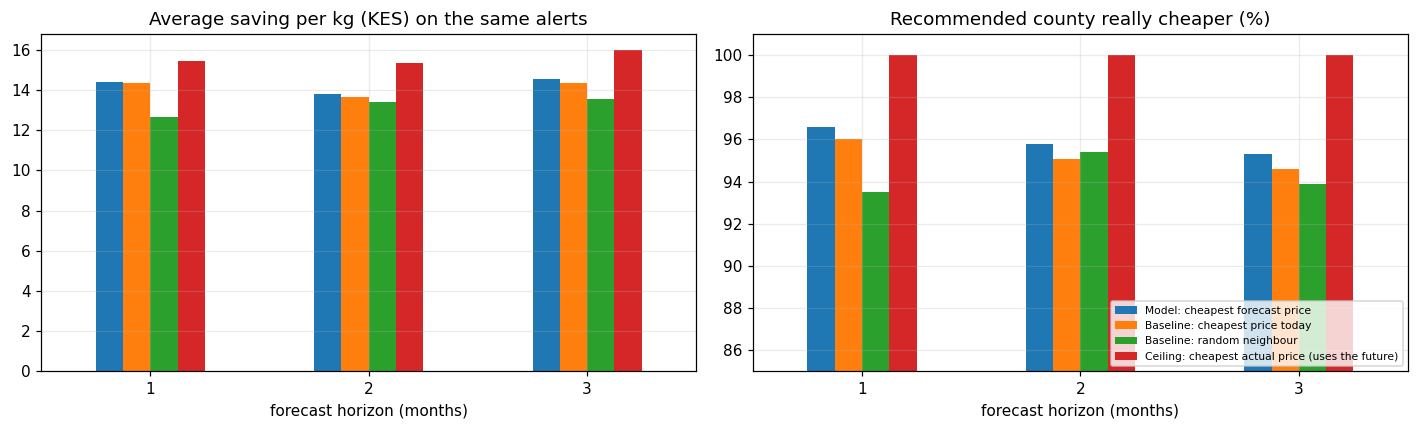

,mean,sd,n,std error
horizon,,,,
1,0.03,1.10,354,0.06
2,0.15,4.96,284,0.29
3,0.21,4.54,278,0.27


Same county picked by the forecast rule and by cheapest-today: 95.7%
Alerts scored: 916 | alert counties: 18 | median distance: 138 km | share where the alert county's price really rose 10%+: 21.2%
By crop: {'Dry Maize': 389, 'Beans Rosecoco': 310, 'Sorghum': 129, 'Red Irish Potatoes': 88} | by price type: {'Wholesale': 690, 'Retail': 226}


In [10]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
w = res.pivot_table(index='horizon', columns='choice', values=['avg saving KES/kg', 'cheaper (hit rate %)'])
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
w['avg saving KES/kg'][list(STRATS.values())].plot.bar(ax=axs[0], rot=0, legend=False); axs[0].set_title('Average saving per kg (KES) on the same alerts'); axs[0].set_xlabel('forecast horizon (months)')
w['cheaper (hit rate %)'][list(STRATS.values())].plot.bar(ax=axs[1], rot=0); axs[1].set_ylim(85, 101); axs[1].set_title('Recommended county really cheaper (%)'); axs[1].set_xlabel('forecast horizon (months)')
axs[1].legend(fontsize=7, loc='lower right'); plt.tight_layout(); plt.show()
f_, n_ = picks['forecast'].loc[common], picks['now'].loc[common]
gain = pd.DataFrame({'extra saving of forecast pick over cheapest-today (KES/kg)': (f_.target_a - f_.target_b).values - (n_.target_a - n_.target_b).values,
                     'horizon': f_.reset_index().horizon.values}).groupby('horizon').agg(mean=('extra saving of forecast pick over cheapest-today (KES/kg)', 'mean'),
                     sd=('extra saving of forecast pick over cheapest-today (KES/kg)', 'std'), n=('horizon', 'size'))
gain['std error'] = gain.sd / np.sqrt(gain.n); display(gain.round(2))
print('Same county picked by the forecast rule and by cheapest-today:', f'{(f_.county_b.values == n_.county_b.values).mean():.1%}')
a_ = f_.reset_index()
print(f"Alerts scored: {len(a_)} | alert counties: {a_.county_a.nunique()} | median distance: {a_.km.median():.0f} km | share where the alert county's price really rose 10%+: {((a_.target_a / a_.origin_a - 1) >= .10).mean():.1%}")
print('By crop:', a_.commodity.value_counts().to_dict(), '| by price type:', a_.price_type.value_counts().to_dict())

In [11]:
fc_ = picks['forecast'].loc[common].reset_index()
print('Extra saving of the forecast pick over cheapest-today (KES/kg, mean +/- std error):', '; '.join(f'{h} month: {r["mean"]:.2f} +/- {r["std error"]:.2f}' for h, r in gain.iterrows()))
print(f'Forecast and cheapest-today pick the same county {(f_.county_b.values == n_.county_b.values).mean():.1%} of the time.')
yr = fc_.origin_month.dt.year.value_counts().sort_index(); print('Alerts by year:', yr.to_dict())
print(f'Alerts followed by a real rise of 10%+ in the alert county: {((fc_.target_a / fc_.origin_a - 1) >= .10).mean():.1%}')

Extra saving of the forecast pick over cheapest-today (KES/kg, mean +/- std error): 1 month: 0.03 +/- 0.06; 2 month: 0.15 +/- 0.29; 3 month: 0.21 +/- 0.27
Forecast and cheapest-today pick the same county 95.7% of the time.
Alerts by year: {2015: 139, 2016: 140, 2017: 119, 2018: 113, 2019: 105, 2020: 57, 2021: 112, 2022: 103, 2023: 18, 2024: 10}
Alerts followed by a real rise of 10%+ in the alert county: 21.2%


**Reading the chart and the extra-saving table.** The model and "cheapest today" bars are almost the same height, and the model's extra saving is within about two standard errors of zero.

**Who got alerts.** The printed lines show the mix of crops, price types and years. Alerts cluster in the years where real county prices exist, so recent years have few. **Only about one alert in five is followed by a real 10% or larger rise in the alert county.** This is the same weak early-warning signal as in notebook 02: the forecast catches a rise only some of the time.

## 5. Sensitivity: how big must the forecast gap be?
We change the minimum forecast gap (the recommended county must be this much cheaper than the alert county). A bigger gap gives fewer, safer recommendations.

In [12]:
rows = []
for mg in (0.0, 0.05, 0.10, 0.20):
    MIN_GAIN = mg
    r, _, _, c_ = evaluate(fc_arima, 'ARIMA')
    r = r[r.choice.isin([STRATS['forecast'], STRATS['now']])].groupby('choice')[['cheaper (hit rate %)', 'avg saving KES/kg', 'avg saving %']].mean().round(2)
    r['min forecast gap'] = f'{mg:.0%}'; r['alerts scored (all horizons)'] = len(c_); rows.append(r.reset_index())
MIN_GAIN = 0.05
sens_tab = pd.concat(rows).set_index(['min forecast gap', 'choice']); display(sens_tab)

cheaper (hit rate %)  avg saving KES/kg  avg saving %  alerts scored (all horizons)
min forecast gap choice                                                                                                             
0%               Baseline: cheapest price today                 94.82              13.27         19.56                          1034
                 Model: cheapest forecast price                 95.13              13.41         19.75                          1034
5%               Baseline: cheapest price today                 95.24              14.12         20.87                           916
                 Model: cheapest forecast price                 95.90              14.25         21.03                           916
10%              Baseline: cheapest price today                 96.45              15.37         22.84                           787
                 Model: cheapest forecast price                 96.98              15.43         22.91                           787
20%              Baseline: cheapest price today                 97.71              18.14         27.18                           517
                 Model: cheapest forecast price                 97.92              18.10         27.06                           517

In [13]:
ORDER_ = ['0%', '5%', '10%', '20%']
h_ = sens_tab['cheaper (hit rate %)'].unstack('choice').loc[ORDER_]; n_al = sens_tab['alerts scored (all horizons)'].groupby(level=0).first()
for g_ in h_.index: print(f'min forecast gap {g_}: model cheaper {h_.loc[g_, STRATS["forecast"]]:.1f}% | cheapest-today {h_.loc[g_, STRATS["now"]]:.1f}% | alerts scored {n_al[g_]}')

min forecast gap 0%: model cheaper 95.1% | cheapest-today 94.8% | alerts scored 1034
min forecast gap 5%: model cheaper 95.9% | cheapest-today 95.2% | alerts scored 916
min forecast gap 10%: model cheaper 97.0% | cheapest-today 96.5% | alerts scored 787
min forecast gap 20%: model cheaper 97.9% | cheapest-today 97.7% | alerts scored 517


**Reading it.** Requiring a bigger gap raises the hit rate for both the model and the baseline while the number of scored alerts falls. The model stays within about one point of the baseline throughout, so the conclusion does not depend on the 5% choice.

## 6. Does the saving survive the trip?
Prices are per kg at the market. A buyer also pays to move the goods, so a saving only counts if it is larger than transport. **No freight rate is assumed from published data here**: I could not find a reliable published KES per tonne-km figure, so the cell works out the **break-even** instead, meaning how expensive transport can be before the saving is used up, using each alert's own saving and distance. The freight rates and trip costs in the tables are **illustrative placeholders to be replaced with a transporter's quote**.

In [14]:
# Does the saving survive the trip? No transport rate is assumed here: the cell works out the BREAK-EVEN, i.e. how expensive transport can be before the saving disappears.
RETURN_FACTOR = 2        # the truck is paid for the trip there and back
tr = picks['forecast'].loc[common].reset_index()
tr['saving_per_kg'] = tr.target_a - tr.target_b
tr['breakeven_per_tonne_km'] = tr.saving_per_kg * 1000 / (RETURN_FACTOR * tr.km)       # KES per tonne per km (charged both ways) at which the saving is exactly used up
q = tr.breakeven_per_tonne_km.quantile([.1, .5, .9]).round(0)
print(f'Mean saving KES {tr.saving_per_kg.mean():.1f}/kg = KES {tr.saving_per_kg.mean() * 1000:,.0f} per tonne | median distance {tr.km.median():.0f} km')
print(f'Break-even freight rate (KES per tonne-km, both ways): 10th percentile {q[.1]:.0f} | median {q[.5]:.0f} | 90th percentile {q[.9]:.0f}')
RATES = [10, 25, 50, 100, 150]      # ILLUSTRATIVE freight rates, KES per tonne-km: replace with a transporter quote
print('Share of alerts where the saving still beats transport, if freight costs this much per tonne-km (illustrative):')
display(pd.Series({f'KES {r}/tonne-km': (tr.breakeven_per_tonne_km > r).mean() for r in RATES}).mul(100).round(1).rename('% of alerts still saving money').to_frame().T)
TRIPS = [2000, 5000, 10000, 20000, 40000]      # ILLUSTRATIVE total cost of one round trip in KES (pick-up to lorry): replace with a quote
be = pd.DataFrame({'round trip cost (KES)': TRIPS}); be['break-even load (kg)'] = (be['round trip cost (KES)'] / tr.saving_per_kg.median()).round(0)
print('Smallest load that makes the median saving worth the trip:'); display(be.set_index('round trip cost (KES)').T)

Mean saving KES 14.3/kg = KES 14,260 per tonne | median distance 138 km
Break-even freight rate (KES per tonne-km, both ways): 10th percentile 7 | median 42 | 90th percentile 108
Share of alerts where the saving still beats transport, if freight costs this much per tonne-km (illustrative):


,KES 10/tonne-km,KES 25/tonne-km,KES 50/tonne-km,KES 100/tonne-km,KES 150/tonne-km
% of alerts still saving money,86.8,69.7,42.4,11.5,3.2


Smallest load that makes the median saving worth the trip:


round trip cost (KES),2000,5000,10000,20000,40000
break-even load (kg),163.0,408.0,816.0,1631.0,3263.0


**How to read it.**
* **Break-even rate:** the freight rate (KES per tonne per km, paid both ways) at which the saving is exactly used up. If a real quote is below the median break-even, most recommendations still save money for a **full lorry load**.
* **Break-even load:** the smallest load for which the median saving pays for one round trip. A small buyer moving one or two bags will not clear a trip cost of several thousand shillings, however large the saving per kg. **The recommendation is therefore for traders and institutions buying in bulk, not for individual households.**
* Savings are also reduced by handling losses, quality differences and market fees, which are not modelled.

## 6. Decision log (recommender)
| # | Decision | Evidence | Why |
|---|---|---|---|
| R1 | Build a **"where to buy"** recommender, not "what to buy instead". | The data has the same crop in many counties; crop substitution would need an outside nutrition table and only has four crops. | It is the version the data supports. "What to buy instead" is a possible extension. |
| R2 | Only the four crops with a chosen ARIMA order; wholesale and retail kept apart. | Harness `ORDERS`. | Same models as the group table, and prices of different types are not comparable. |
| R3 | "Nearby" = county centres within 200 km. | 596 pairs, median 15 neighbours per county. | Gives every county at least one neighbour without crossing the country. Road distance is not available. |
| R4 | Alert = top 20% of counties by forecast rise (above zero). | A fixed threshold almost never fires (notebook 02). | Rank-based alerts always produce candidates. |
| R5 | Recommend only counties with a **real price at the alert month**; score only where both have a real price at the target month. | Observed targets are 7.4% of rows. | Estimated prices are partly copied from neighbouring counties, so comparing them would be circular. |
| R6 | Minimum forecast gap 5%. | Sensitivity table, 0% to 20%. | Result is stable; 5% keeps most alerts. |
| R7 | Judge the forecast against **cheapest today** on identical alerts. | Extra saving is small and within its standard error (section 4). | The question is whether the forecast adds value, not whether moving to a cheaper county saves money. |
| R8 | Backtest 2015-2024 only; 2025-26 untouched. | Group rule: the test opens once on Day 5. | Nothing here is chosen from the test window. |
| R9 | Test transport with a **break-even** analysis, not an assumed freight rate. | No reliable published KES per tonne-km figure was found. | The conclusion does not depend on a number we cannot source; rates in the tables are placeholders. |

## Summary and limits
**Result.** Pointing a buyer to a cheaper nearby county after a rise alert is right in almost every scored case and saves a double-digit percentage of the price in the 2015-2024 backtest (exact figures printed in section 4). **The forecast contributes almost none of that.** "Cheapest nearby county today" does about as well, and the ARIMA forecast changes the pick only a few percent of the time.

**What to say.** "We tested a recommender that suggests a cheaper nearby market. It works, but because county prices differ a lot and the gaps last, not because the forecast is clever. The forecast layer is not yet justified; the Day 5 model should be dropped into this notebook to see whether a better forecast changes that. After transport, the saving holds for bulk buyers but not for small ones."

**Limits.**
* The scored alerts come from a few counties, mostly earlier years, mostly wholesale maize and beans.
* Savings are price differences between counties and exclude handling, quality and market fees. Transport is covered only by the break-even analysis in section 6, not by a real freight rate.
* Only real (observed) prices are scored, so the recommender is evaluated where county prices are actually reported.
* Alerts are weak: only about one in five is followed by a real rise of 10% or more.
